In [1]:
#importar las librerías
#librería utilizada para graficar
import matplotlib.pyplot as plt
#librería que me permite trabajar con estructuras complejas, como Grafos
import networkx as nx

In [2]:
#Creamos una instancia de la clase Graph
#Graph es una colección de nodos
grafoBeach = nx.Graph()

In [3]:
grafoBeach.add_weighted_edges_from(
    [
    ("B", "A", 20),
    ("A", "C", 10),
    ("B", "D", 15),
    ("C", "D", 10),
    ("C", "E", 25)
    ]
)

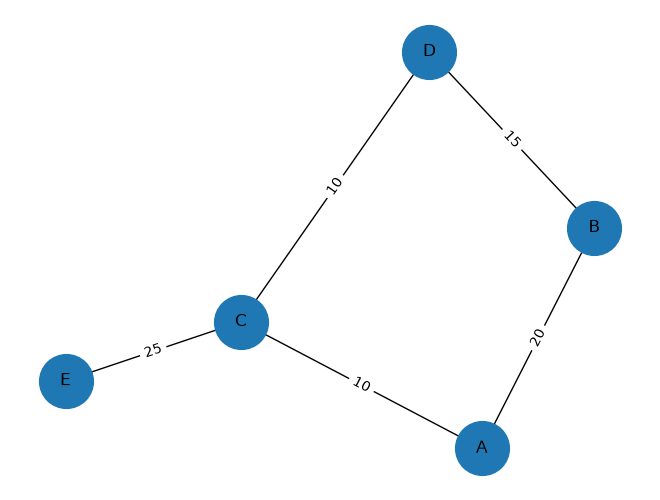

In [4]:
pos = nx.spring_layout(
    grafoBeach,
    seed=10
)
nx.draw(
    grafoBeach,
    pos,
    with_labels=True,
    node_size=1500
)
labels = nx.get_edge_attributes(
    grafoBeach,
    "weight"
)
nx.draw_networkx_edge_labels(
    grafoBeach,
    pos,
    edge_labels=labels
)
plt.show()

In [5]:
# Mostramos rutas y pesos
rutas = list(
    nx.all_simple_paths(
        grafoBeach,
        source = "B",
        target = "E"
    )
)

def costo_ruta(grafoBeach, ruta):
    costo = 0
    for i in range(len (ruta) - 1):
        costo += grafoBeach[ruta[i]][ruta[i+1]]["weight"]
    return costo

for i,ruta in enumerate(rutas,start = 1):
    costo = costo_ruta(grafoBeach,ruta)
    print(f"Ruta{i}:{costo} minutos")

Ruta1:55 minutos
Ruta2:50 minutos


In [6]:
costos = [costo_ruta(grafoBeach, ruta) for ruta in rutas]

mejorCamino = costos.index(min(costos))

print(f"La ruta {mejorCamino + 1} es la mejor opción")
print(f"Tiempo estimado: {costos[mejorCamino]} minutos")
print("Ruta seleccionada:")
print(rutas[mejorCamino])

La ruta 2 es la mejor opción
Tiempo estimado: 50 minutos
Ruta seleccionada:
['B', 'D', 'C', 'E']
